In [1]:
# Setup:

import os, random, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
DATA_DIR = r"C:\Users\USER\Datamites Projects\Project 2\PRCP-1001-RiceLeaf\Data"

Duplicates removed: 1
label
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64 
 img_size
(3081, 897)    85
(250, 200)      2
(946, 255)      1
(1200, 900)     1
(376, 80)       1
Name: count, dtype: int64


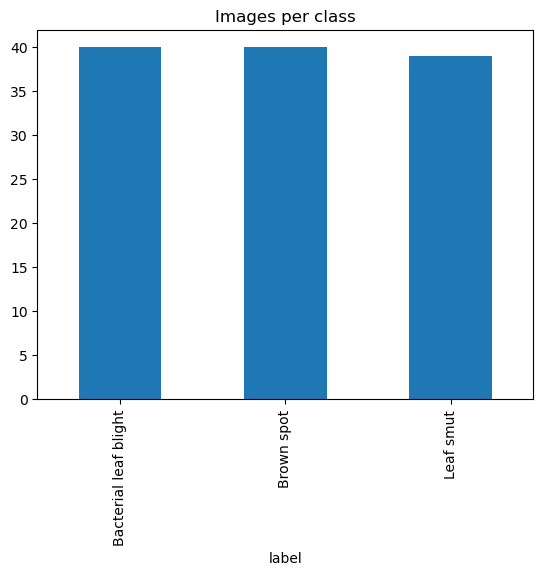

In [2]:
# Load data and EDA:

df = pd.DataFrame([{"filepath": os.path.join(DATA_DIR, c, f), "label": c}
                   for c in os.listdir(DATA_DIR) for f in os.listdir(os.path.join(DATA_DIR, c))])

# remove duplicate images (they would leak between train and test)
df["hash"] = df.filepath.apply(lambda p: hashlib.md5(open(p, "rb").read()).hexdigest())
print("Duplicates removed:", df.hash.duplicated().sum())
df = df.drop_duplicates("hash")

df["img_size"] = df.filepath.apply(lambda p: Image.open(p).size)
print(df.label.value_counts(), "\n", df.img_size.value_counts().head())
df.label.value_counts().plot(kind="bar", title="Images per class"); plt.show()

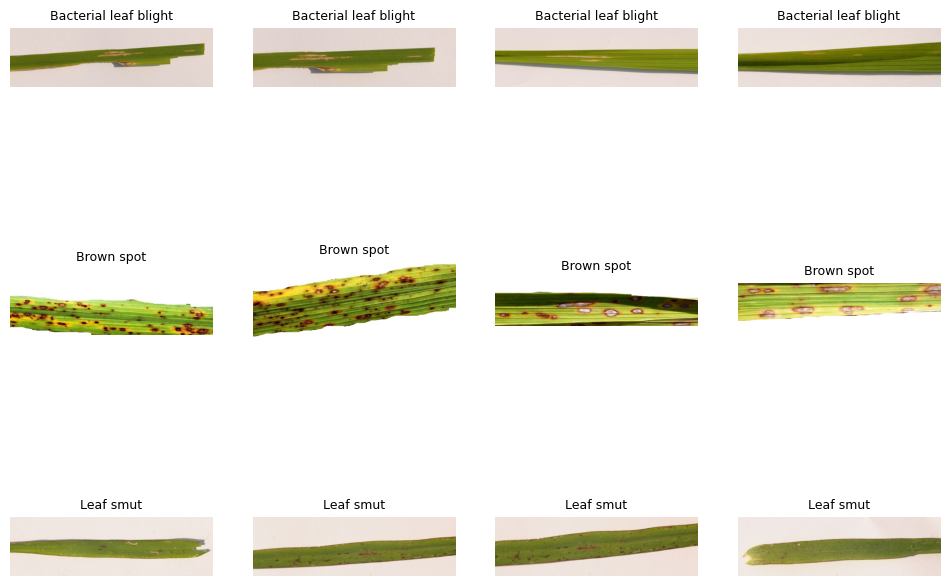

In [3]:
# Sample images:

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
samples = df.groupby("label").head(4).sort_values("label")
for ax, (_, r) in zip(axes.flat, samples.iterrows()):
    ax.imshow(Image.open(r.filepath)); ax.set_title(r.label, fontsize=9); ax.axis("off")
plt.show()

In [4]:
# Split 70/15/15:

train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df.label, random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

83 18 18


In [5]:
# Data generators:

aug = dict(rotation_range=20, zoom_range=0.15, width_shift_range=0.1, height_shift_range=0.1,
           horizontal_flip=True, vertical_flip=True, brightness_range=(0.8, 1.2))
args = dict(x_col="filepath", y_col="label", target_size=(224, 224),
            class_mode="categorical", batch_size=16)

plain = ImageDataGenerator(preprocessing_function=preprocess_input)
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input, **aug).flow_from_dataframe(train_df, seed=SEED, **args)
val_gen = plain.flow_from_dataframe(val_df, shuffle=False, **args)
test_gen = plain.flow_from_dataframe(test_df, shuffle=False, **args)

Found 83 validated image filenames belonging to 3 classes.
Found 18 validated image filenames belonging to 3 classes.
Found 18 validated image filenames belonging to 3 classes.


In [6]:
# Model:

base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False

mobilenet = models.Sequential([base, layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"), layers.Dropout(0.5), layers.Dense(3, activation="softmax")])

baseline = models.Sequential([layers.Input((224, 224, 3)),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(), layers.Dense(64, activation="relu"),
    layers.Dropout(0.5), layers.Dense(3, activation="softmax")])

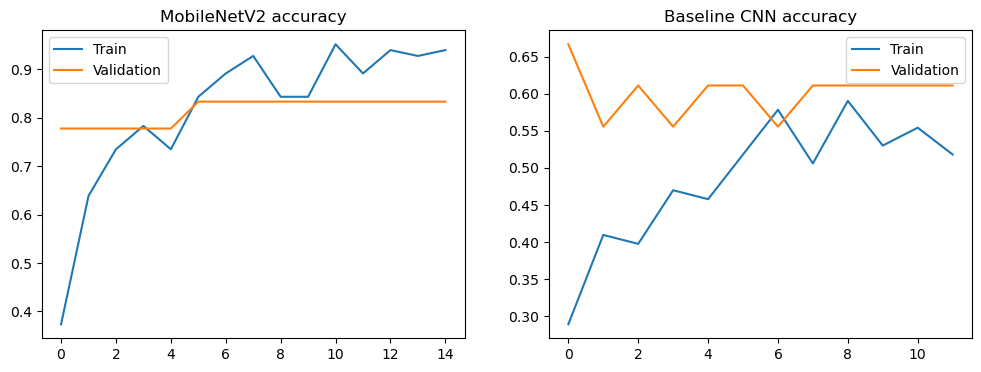

In [7]:
# Train both models:

callbacks = [EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
             ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]

models_dict = {"MobileNetV2": mobilenet, "Baseline CNN": baseline}
histories = {}
for name, m in models_dict.items():
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    histories[name] = m.fit(train_gen, validation_data=val_gen, epochs=30, callbacks=callbacks, verbose=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h.history["accuracy"], label="Train"); ax.plot(h.history["val_accuracy"], label="Validation")
    ax.set_title(name + " accuracy"); ax.legend()
plt.show()

===== MobileNetV2 =====
                       precision    recall  f1-score   support

Bacterial leaf blight       0.86      1.00      0.92         6
           Brown spot       0.83      0.83      0.83         6
            Leaf smut       1.00      0.83      0.91         6

             accuracy                           0.89        18
            macro avg       0.90      0.89      0.89        18
         weighted avg       0.90      0.89      0.89        18



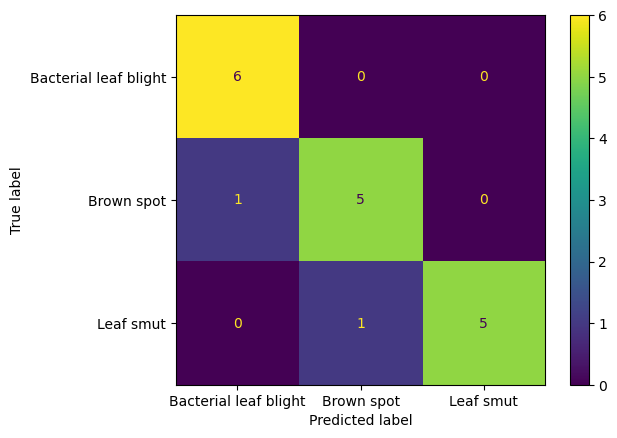

===== Baseline CNN =====
                       precision    recall  f1-score   support

Bacterial leaf blight       0.38      0.50      0.43         6
           Brown spot       0.43      0.50      0.46         6
            Leaf smut       0.00      0.00      0.00         6

             accuracy                           0.33        18
            macro avg       0.27      0.33      0.30        18
         weighted avg       0.27      0.33      0.30        18



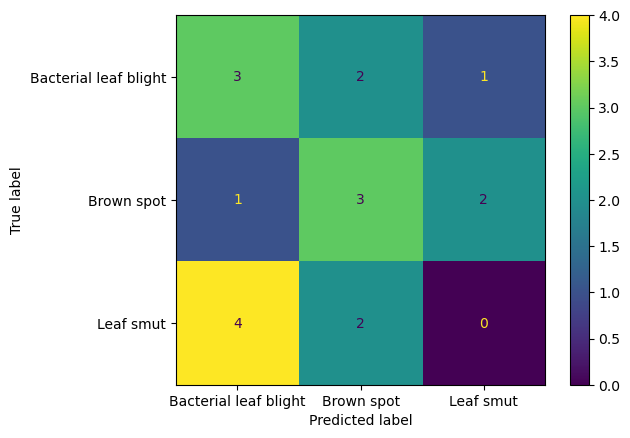

In [8]:
# Test set evaluation:

y_true, names = test_gen.classes, list(test_gen.class_indices)
for name, m in models_dict.items():
    y_pred = m.predict(test_gen, verbose=0).argmax(axis=1)
    print("=====", name, "=====")
    print(classification_report(y_true, y_pred, target_names=names))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=names); plt.show()

In [9]:
# Comparison table:
pd.DataFrame({name: {"Val Acc": m.evaluate(val_gen, verbose=0)[1],
                     "Test Acc": m.evaluate(test_gen, verbose=0)[1],
                     "Parameters": m.count_params()}
              for name, m in models_dict.items()}).T.round(3)

,Val Acc,Test Acc,Parameters
MobileNetV2,0.833,0.889,2340163.0
Baseline CNN,0.556,0.333,101699.0
